In [12]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv('instagram_style_content_moderation_dataset.csv')

Safe = 5000
Toxic = 5000


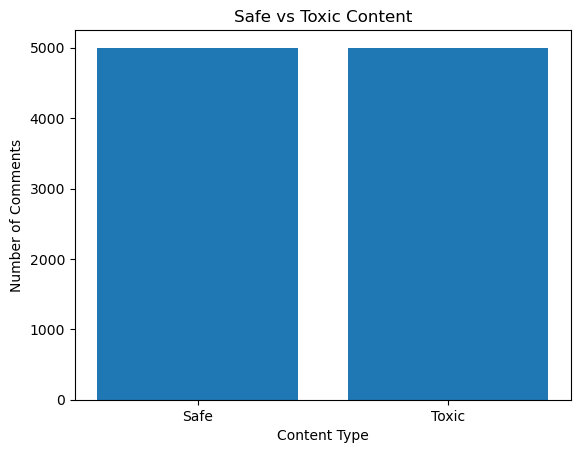

In [8]:
#Overall Safe vs Toxic
counts = df["label"].value_counts()
safe = counts.get(0, 0)
toxic = counts.get(1, 0)
print('Safe =',safe)
print('Toxic =',toxic)
plt.bar(["Safe", "Toxic"], [safe, toxic])
plt.xlabel("Content Type")
plt.ylabel("Number of Comments")
plt.title("Safe vs Toxic Content")
plt.show()

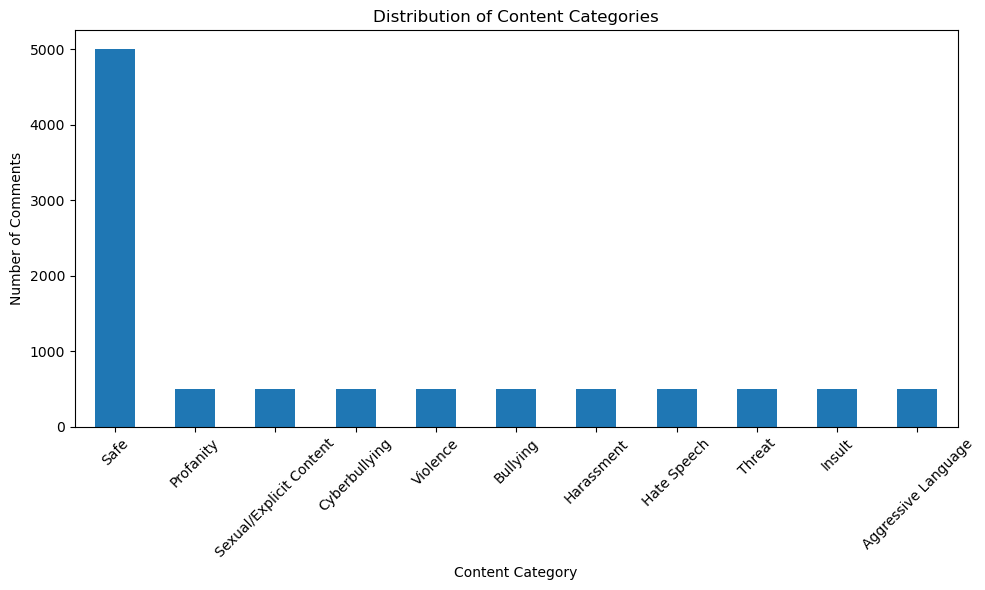

In [13]:
#Categories
category_counts = df["category"].value_counts()
plt.figure(figsize=(10, 6))
category_counts.plot(kind="bar")
plt.xlabel("Content Category")
plt.ylabel("Number of Comments")
plt.title("Distribution of Content Categories")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

0 (Safe)
1 (Mild)
2 (Moderate)
3 (Severe)


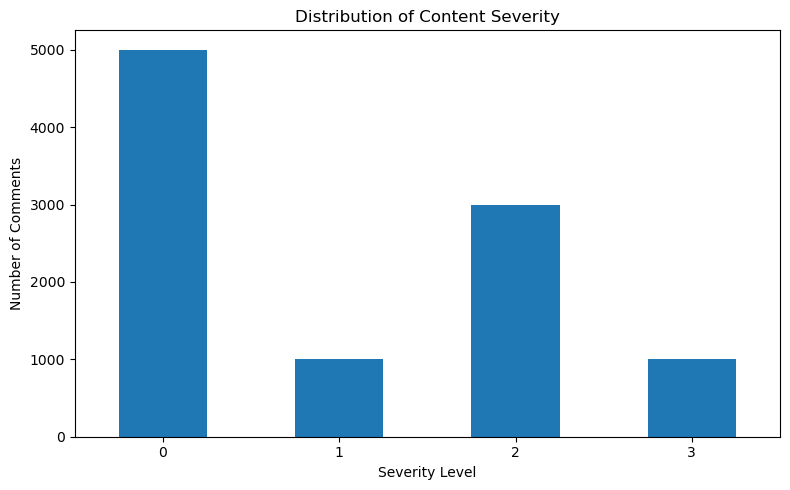

In [10]:
#severity graph
print('0 (Safe)\n1 (Mild)\n2 (Moderate)\n3 (Severe)')   
severity_counts = df["severity"].value_counts().sort_index()
plt.figure(figsize=(8, 5))
severity_counts.plot(kind="bar")
plt.xlabel("Severity Level")
plt.ylabel("Number of Comments")
plt.title("Distribution of Content Severity")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:

#Data Quality check
# Missing values
print("Missing values:")
print(df.isnull().sum())

# Duplicate text
print("\nDuplicate texts:", df["text"].duplicated().sum())

# Duplicate IDs
print("Duplicate IDs:", df["id"].duplicated().sum())

# Label distribution
print("\nLabels:")
print(df["label"].value_counts())

# Severity distribution
print("\nSeverity:")
print(df["severity"].value_counts().sort_index())

# Category distribution
print("\nCategories:")
print(df["category"].value_counts())

Missing values:
id             0
text           0
label          0
category       0
severity       0
targeted       0
explanation    0
dtype: int64

Duplicate texts: 0
Duplicate IDs: 0

Labels:
label
0    5000
1    5000
Name: count, dtype: int64

Severity:
severity
0    5000
1    1000
2    3000
3    1000
Name: count, dtype: int64

Categories:
category
Safe                       5000
Profanity                   500
Sexual/Explicit Content     500
Cyberbullying               500
Violence                    500
Bullying                    500
Harassment                  500
Hate Speech                 500
Threat                      500
Insult                      500
Aggressive Language         500
Name: count, dtype: int64


In [15]:
from sklearn.model_selection import train_test_split

X = df["text"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 8000
Testing samples: 2000


In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=10000,
    stop_words="english"
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training shape:", X_train_tfidf.shape)
print("Testing shape:", X_test_tfidf.shape)

Training shape: (8000, 659)
Testing shape: (2000, 659)


In [17]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_tfidf, y_train)

print("Model training completed!")

Model training completed!


In [19]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["SAFE", "TOXIC"]
))

Accuracy: 0.9915

Classification Report:
              precision    recall  f1-score   support

        SAFE       0.99      0.99      0.99      1000
       TOXIC       0.99      0.99      0.99      1000

    accuracy                           0.99      2000
   macro avg       0.99      0.99      0.99      2000
weighted avg       0.99      0.99      0.99      2000



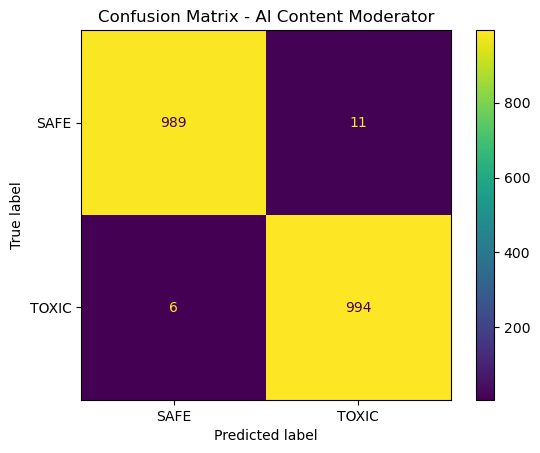

In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["SAFE", "TOXIC"]
)

disp.plot()
plt.title("Confusion Matrix - AI Content Moderator")
plt.show()

In [21]:
new_comments = [
    "I really enjoyed this movie.",
    "You are an idiot.",
    "Thank you for helping me.",
    "Nobody wants to hear your stupid opinion."
]

new_comments_tfidf = tfidf.transform(new_comments)

predictions = model.predict(new_comments_tfidf)

for comment, prediction in zip(new_comments, predictions):
    result = "TOXIC" if prediction == 1 else "SAFE"
    print(f"{comment} → {result}")

I really enjoyed this movie. → SAFE
You are an idiot. → SAFE
Thank you for helping me. → SAFE
Nobody wants to hear your stupid opinion. → TOXIC


In [22]:
model.fit(X_train_tfidf, y_train)

LogisticRegression(max_iter=1000)

In [23]:
import joblib

joblib.dump(model, "model.pkl")
joblib.dump(tfidf, "tfidf.pkl")

print("Model and TF-IDF vectorizer saved successfully!")

Model and TF-IDF vectorizer saved successfully!


2026-08-13 17:02:15.395 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-13 17:02:15.398 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-13 17:02:16.351 
  command:

    streamlit run C:\Users\USER\anaconda3\Lib\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-08-13 17:02:16.352 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-13 17:02:16.354 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-13 17:02:16.355 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-13 17:02:16.356 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when runni